# H1 Model Experiments: Does opponent strength change the Team A vs. Team C comparison?

This notebook follows `H1_Plan.md`. It runs walk-forward validation for two Bayesian networks, scores them with the Brier score, logs every run in MLflow, scores the selected model once on 2026, and compares Team A and Team C on shared 2026 situations.

**Folder layout:** keep this notebook in the same folder as `h1_fold_data.csv`, `h1_fold_manifest.csv`, `h1_game_level.csv`, and `h1_shared_2026_scenarios.csv`. Outputs are written to `results/H1/` (with `figures/` and `predictions/` inside), and MLflow stores runs in `mlflow.db` (SQLite) and files in `mlartifacts/` in this folder.

## 1. Explain the question

**H1:** If Team C's higher win rate is mainly due to facing weaker opponents, then Team A will have a higher estimated chance of winning than Team C after we account for opponent strength.

In simple terms: does the comparison between Team A and Team C change once we account for the teams they played?

We compare two Bayesian networks that estimate the probability a team wins:

| Model | Inputs |
|---|---|
| **Baseline** | `focal_rating_group`, `focal_location` |
| **Opponent-adjusted** | `focal_rating_group`, `focal_location`, `opponent_rating_group` |

Both models use the same data, folds, target, software, fitting settings, and scoring method. **They differ only by whether `opponent_rating_group` is included.**

In [ ]:
import sys, re, json, warnings, platform
from pathlib import Path
import importlib.metadata as md_

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import mlflow
import pgmpy
from IPython.display import display, Markdown

try:  # pgmpy >= 1.0
    from pgmpy.models import DiscreteBayesianNetwork
except ImportError:  # older pgmpy
    from pgmpy.models import BayesianNetwork as DiscreteBayesianNetwork

from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

LIB_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "mlflow": mlflow.__version__,
    "pgmpy": md_.version("pgmpy"),
}
print(json.dumps(LIB_VERSIONS, indent=2))

# Find the repository root whether Jupyter starts in the repo or notebooks/.
cwd = Path.cwd().resolve()
ROOT = next(
    (
        path
        for path in (cwd, *cwd.parents)
        if (path / "prepared_data" / "H1" / "h1_fold_data.csv").exists()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Could not find the repository root containing "
        "prepared_data/H1/h1_fold_data.csv."
    )

DATA_DIR = ROOT / "prepared_data" / "H1"
OUT_DIR = ROOT / "results" / "H1"
FIG_DIR = OUT_DIR / "figures"
PRED_DIR = OUT_DIR / "predictions"
MLFLOW_DIR = ROOT / "mlflow" / "H1"

for folder in (OUT_DIR, FIG_DIR, PRED_DIR, MLFLOW_DIR):
    folder.mkdir(parents=True, exist_ok=True)

assert (DATA_DIR / "h1_fold_data.csv").exists(), (
    f"Could not find h1_fold_data.csv in {DATA_DIR}"
)

print("Repository root:", ROOT)
print("Data folder:    ", DATA_DIR)
print("Results folder: ", OUT_DIR)
print("MLflow folder:  ", MLFLOW_DIR)

## 2. Load and check the prepared files

* `h1_fold_data.csv`: training, validation, and the final 2026 test (one row per team perspective in a game).
* `h1_fold_manifest.csv`: the training seasons, held-out season, and rating cutoffs for each fold. Used to confirm the split.
* `h1_shared_2026_scenarios.csv`: the same opponent-and-location situations for Team A and Team C, with no outcomes. Used only for the Team A–Team C comparison.
* `h1_game_level.csv`: original numeric ratings; used only to confirm that the fold file contains the same games.

Notes on the data: `h1_fold_data.csv` repeats each game once per fold, so we keep one row per team-game before building the folds. Location is `Unknown` for all 2019 games; it is kept as its own location state.

The checks below confirm the required columns exist, outcomes and rating groups have expected values, and the fold assignments match the manifest.

In [2]:
# ---- Config -------------------------------------------------------------------
SEASON_COL = "season"
TARGET = "outcome"
BINARY = "outcome_binary"
RATING_GROUPS = ["low", "medium", "high"]
SCEN_ID, TEAM_COL = "scenario_id", "focal_team_id"
# Team ids in h1_shared_2026_scenarios.csv. Mapping confirmed for H1: Team A = 1105 (rating group: high), Team C = 1120 (rating group: medium).
TEAM_A_ID = 1105
TEAM_C_ID = 1120
# -----------------------------------------------------------------------------

fold_data = pd.read_csv(DATA_DIR / "h1_fold_data.csv")
manifest = pd.read_csv(DATA_DIR / "h1_fold_manifest.csv")
scenarios = pd.read_csv(DATA_DIR / "h1_shared_2026_scenarios.csv")
game_level = pd.read_csv(DATA_DIR / "h1_game_level.csv")

def parse_seasons(text):
    return sorted(int(y) for y in re.findall(r"\d{4}", str(text)))

print("fold_data:", fold_data.shape, "| manifest:", manifest.shape, "| scenarios:", scenarios.shape, "| game_level:", game_level.shape)

# --- Required columns ---------------------------------------------------------
INPUT_COLS_ALL = ["focal_rating_group", "focal_location", "opponent_rating_group"]
FOLD_COL, ROLE_COL = "fold", "data_role"
required = INPUT_COLS_ALL + [TARGET, BINARY, SEASON_COL, "game_id", "focal_team_id", FOLD_COL, ROLE_COL]
missing = [c for c in required if c not in fold_data.columns]
assert not missing, f"h1_fold_data.csv is missing columns: {missing}"
m_missing = [c for c in ["fold", "training_seasons", "heldout_season", "heldout_role"] if c not in manifest.columns]
assert not m_missing, f"manifest is missing columns: {m_missing}"
s_missing = [c for c in [SCEN_ID, TEAM_COL] + INPUT_COLS_ALL if c not in scenarios.columns]
assert not s_missing, f"scenarios file is missing columns: {s_missing}"
assert not any(c in scenarios.columns for c in (TARGET, BINARY)), "Scenarios file must not contain outcomes."

# --- Value checks -------------------------------------------------------------
assert set(fold_data[TARGET].unique()) <= {"win", "loss"}, fold_data[TARGET].unique()
assert (fold_data[BINARY] == (fold_data[TARGET] == "win").astype(int)).all(), "outcome_binary disagrees with outcome"
for df_name, df in (("fold_data", fold_data), ("scenarios", scenarios)):
    for c in ("focal_rating_group", "opponent_rating_group"):
        bad = set(df[c].unique()) - set(RATING_GROUPS)
        assert not bad, f"{df_name}.{c} has unexpected values: {bad}"
    assert df[INPUT_COLS_ALL].notna().all().all(), f"{df_name} has missing model inputs"
assert fold_data[[TARGET, BINARY]].notna().all().all()

# --- fold_data repeats each game once per fold; keep one row per team-game -------------
base_df = fold_data.drop_duplicates(subset=["game_id", "focal_team_id"]).copy()
assert not fold_data.groupby(["game_id", "focal_team_id"])[INPUT_COLS_ALL + [TARGET]].nunique().gt(1).any().any(), \
    "A repeated team-game row has different values in different folds"
assert len(base_df) == len(game_level), "Unique team-game rows do not match h1_game_level.csv"
assert set(base_df["game_id"]) == set(game_level["game_id"])
assert 2020 not in set(base_df[SEASON_COL]), "2020 should not appear in the prepared data"
print(f"fold_data rows: {len(fold_data):,} -> unique team-game rows: {len(base_df):,} (matches h1_game_level.csv)")

# NOTE: location is 'Unknown' for every 2019 row; other seasons use H / A / N.
print("\nLocation by season (unique team-game rows):")
display(base_df.groupby([SEASON_COL, "focal_location"]).size().unstack(fill_value=0))

# --- Manifest -> FOLDS (validation) and the final 2026 fit ------------------------------
EXPECTED_HELDOUT = [2021, 2022, 2023, 2024, 2025]
FOLDS = [{"fold": r["fold"], "train_seasons": parse_seasons(r["training_seasons"]), "heldout_season": int(r["heldout_season"])}
         for _, r in manifest[manifest["heldout_role"] == "validation"].iterrows()]
FOLDS = sorted(FOLDS, key=lambda f: f["heldout_season"])
assert [f["heldout_season"] for f in FOLDS] == EXPECTED_HELDOUT
for f in FOLDS:   # training = 2015-2019 plus every earlier post-2020 season, never 2020
    exp = [y for y in range(2015, f["heldout_season"]) if y != 2020]
    assert f["train_seasons"] == exp, (f["fold"], f["train_seasons"], exp)
final_row = manifest[manifest["heldout_role"] == "test"].iloc[0]
FINAL_FOLD = final_row["fold"]
FINAL_TRAIN_SEASONS = parse_seasons(final_row["training_seasons"])
assert int(final_row["heldout_season"]) == 2026 and FINAL_TRAIN_SEASONS == [y for y in range(2015, 2026) if y != 2020]
print("\nCutoffs (low/medium, medium/high):", manifest[["low_medium_cutoff", "medium_high_cutoff"]].drop_duplicates().values.tolist())

# --- Fold labels in the data must match the manifest ----------------------------------
for _, r in manifest.iterrows():
    sub = fold_data[fold_data[FOLD_COL] == r["fold"]]
    tr = sorted(sub.loc[sub[ROLE_COL] == "train", SEASON_COL].unique())
    ho = sorted(sub.loc[sub[ROLE_COL] == r["heldout_role"], SEASON_COL].unique())
    assert tr == parse_seasons(r["training_seasons"]), (r["fold"], tr)
    assert ho == [int(r["heldout_season"])], (r["fold"], ho)
for f in FOLDS:
    n_tr = base_df[SEASON_COL].isin(f["train_seasons"]).sum()
    n_ho = (base_df[SEASON_COL] == f["heldout_season"]).sum()
    print(f"{f['fold']}: train {f['train_seasons'][0]}-{f['train_seasons'][-1]} excl. 2020 (n={n_tr:,}), held-out {f['heldout_season']} (n={n_ho:,})")
assert (base_df[SEASON_COL] == 2026).sum() > 0, "No 2026 rows found for the final test"

# --- Scenario checks + Team A / Team C identification ---------------------------------
assert set(scenarios[TEAM_COL]) == {TEAM_A_ID, TEAM_C_ID}, f"Scenario team ids are {sorted(scenarios[TEAM_COL].unique())}"
scenarios["team_label"] = scenarios[TEAM_COL].map({TEAM_A_ID: "Team A", TEAM_C_ID: "Team C"})
assert (scenarios.groupby(SCEN_ID)["team_label"].nunique() == 2).all(), "Each scenario needs one Team A row and one Team C row"
assert (scenarios.groupby(SCEN_ID)[["focal_location", "opponent_rating_group"]].nunique() == 1).all().all(), \
    "Team A and Team C must face the same opponent and location within a scenario"
print(f"\nScenarios: {scenarios[SCEN_ID].nunique()} situations x 2 teams = {len(scenarios)} rows")
print(scenarios.groupby("team_label")["focal_rating_group"].unique().to_string())
print(f"Team A = id {TEAM_A_ID}, Team C = id {TEAM_C_ID} (confirmed mapping)")
print("All checks passed.")

fold_data: (517314, 14) | manifest: (6, 6) | scenarios: (116, 7) | game_level: (112608, 10)
fold_data rows: 517,314 -> unique team-game rows: 112,608 (matches h1_game_level.csv)

Location by season (unique team-game rows):


focal_location,A,H,N,Unknown
season,,,,
2015,4787,4787,830,0
2016,4800,4800,846,0
2017,4802,4802,832,0
2018,4848,4848,798,0
2019,0,0,0,10520
2021,3611,3611,312,0
2022,4868,4868,816,0
2023,4828,4828,892,0
2024,4893,4893,768,0



Cutoffs (low/medium, medium/high): [[-4.4, 4.9]]
validation_2021: train 2015-2019 excl. 2020 (n=52,300), held-out 2021 (n=7,534)
validation_2022: train 2015-2021 excl. 2020 (n=59,834), held-out 2022 (n=10,552)
validation_2023: train 2015-2022 excl. 2020 (n=70,386), held-out 2023 (n=10,548)
validation_2024: train 2015-2023 excl. 2020 (n=80,934), held-out 2024 (n=10,554)
validation_2025: train 2015-2024 excl. 2020 (n=91,488), held-out 2025 (n=10,576)

Scenarios: 58 situations x 2 teams = 116 rows
team_label
Team A      [high]
Team C    [medium]
Team A = id 1105, Team C = id 1120 (confirmed mapping)
All checks passed.


## 3. Set the model inputs

`outcome` (`win` / `loss`) is what the models predict. `outcome_binary` (1 / 0) is used **only afterwards** to compute Brier scores and is never a model input.

In [3]:
BASELINE_INPUTS = ["focal_rating_group", "focal_location"]
OPPONENT_ADJ_INPUTS = ["focal_rating_group", "focal_location", "opponent_rating_group"]
MODELS = {"Baseline": BASELINE_INPUTS, "Opponent-adjusted": OPPONENT_ADJ_INPUTS}
MODEL_NAMES = list(MODELS)

for name, cols in MODELS.items():
    assert TARGET not in cols and BINARY not in cols
    print(f"{name:18s} inputs: {cols}")
print("Target:", TARGET)

Baseline           inputs: ['focal_rating_group', 'focal_location']
Opponent-adjusted  inputs: ['focal_rating_group', 'focal_location', 'opponent_rating_group']
Target: outcome


## 4. Define the two Bayesian networks

Both are discrete Bayesian networks built with **pgmpy**. Each input is a parent of `outcome`:

* **Baseline:** `focal_rating_group → outcome ← focal_location`
* **Opponent-adjusted:** the same, plus `opponent_rating_group → outcome`

Both are fitted with the same estimator and settings (a Bayesian estimator with a BDeu Dirichlet prior, so combinations missing from the training data still get a sensible probability). The settings are fixed across every fold and both models. The probability of `outcome = win` is obtained by exact inference (variable elimination).

In [4]:
SETTINGS = {
    "software": "pgmpy",
    "pgmpy_version": LIB_VERSIONS["pgmpy"],
    "network_class": DiscreteBayesianNetwork.__name__,
    "estimator": "BayesianEstimator",
    "prior_type": "BDeu",
    "equivalent_sample_size": 10,
    "inference": "VariableElimination (exact)",
    "structure": "each input column -> outcome (fixed, not learned)",
}

# Fix the state space once so unseen combinations never break inference
STATE_NAMES = {c: sorted(set(base_df[c]) | set(scenarios[c])) for c in INPUT_COLS_ALL}
STATE_NAMES[TARGET] = ["loss", "win"]
print(json.dumps(SETTINGS, indent=2)); print("State names:", STATE_NAMES)

def build_network(inputs):
    return DiscreteBayesianNetwork([(c, TARGET) for c in inputs])

def fit_model(model_name, train_df):
    inputs = MODELS[model_name]
    data = train_df[inputs + [TARGET]]
    net = build_network(inputs)
    estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})
    net.add_cpds(*estimator.get_parameters(
        prior_type=SETTINGS["prior_type"],
        equivalent_sample_size=SETTINGS["equivalent_sample_size"],
    ))
    assert net.check_model()
    return net

def predict_win_prob(net, X):
    # P(outcome = win | inputs) for each row; inference is run once per unique input combination
    infer = VariableElimination(net)
    cols = list(X.columns)
    keys = list(X.itertuples(index=False, name=None))
    lookup = {}
    for k in set(keys):
        q = infer.query([TARGET], evidence=dict(zip(cols, k)), show_progress=False)
        lookup[k] = float(q.values[q.state_names[TARGET].index("win")])
    return np.array([lookup[k] for k in keys])

def brier(y_binary, p):
    return float(np.mean((np.asarray(y_binary) - np.asarray(p)) ** 2))

# Worked example from the plan: p = 0.72 -> win 0.0784, loss 0.5184
assert abs(brier([1], [0.72]) - 0.0784) < 1e-9 and abs(brier([0], [0.72]) - 0.5184) < 1e-9

{
  "software": "pgmpy",
  "pgmpy_version": "1.1.2",
  "network_class": "DiscreteBayesianNetwork",
  "estimator": "BayesianEstimator",
  "prior_type": "BDeu",
  "equivalent_sample_size": 10,
  "inference": "VariableElimination (exact)",
  "structure": "each input column -> outcome (fixed, not learned)"
}
State names: {'focal_rating_group': ['high', 'low', 'medium'], 'focal_location': ['A', 'H', 'N', 'Unknown'], 'opponent_rating_group': ['high', 'low', 'medium'], 'outcome': ['loss', 'win']}


## 5. Run walk-forward validation for both models

Each fold trains on earlier seasons and predicts one later season (2020 is skipped; all games from a season stay together). In every fold, **both models use exactly the same training rows and held-out rows**. For each fold and model we fit on the training rows, predict `P(outcome = win)` for the training and held-out rows, and save the predictions. That gives 2 models × 5 folds = 10 validation runs.

In [5]:
all_preds = []
for f in FOLDS:
    train_df = base_df[base_df[SEASON_COL].isin(f["train_seasons"])]
    held_df = base_df[base_df[SEASON_COL] == f["heldout_season"]]
    assert not set(train_df.index) & set(held_df.index)
    for m in MODEL_NAMES:
        net = fit_model(m, train_df)
        parts = []
        for role, part in (("train", train_df), ("validation", held_df)):
            p = predict_win_prob(net, part[MODELS[m]])
            parts.append(pd.DataFrame({
                "model": m, "fold": f["fold"], "heldout_season": f["heldout_season"],
                "data_role": role, "season": part[SEASON_COL].values,
                "outcome": part[TARGET].values, "outcome_binary": part[BINARY].values,
                "p_win": p}))
        run_preds = pd.concat(parts, ignore_index=True)
        run_preds.to_csv(PRED_DIR / f"{m.replace(' ', '_').lower()}__{f['fold']}.csv", index=False)
        all_preds.append(run_preds)
    print(f"{f['fold']}: fitted both models (train n={len(train_df):,}, held-out {f['heldout_season']} n={len(held_df):,})")

pred_all = pd.concat(all_preds, ignore_index=True)
assert pred_all.groupby(["model", "fold"]).ngroups == 10
pred_all.head()

C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})
C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})


validation_2021: fitted both models (train n=52,300, held-out 2021 n=7,534)


C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})
C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})


validation_2022: fitted both models (train n=59,834, held-out 2022 n=10,552)


C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})
C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})


validation_2023: fitted both models (train n=70,386, held-out 2023 n=10,548)


C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})
C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})


validation_2024: fitted both models (train n=80,934, held-out 2024 n=10,554)


C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})
C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})


validation_2025: fitted both models (train n=91,488, held-out 2025 n=10,576)


,model,fold,heldout_season,data_role,season,outcome,outcome_binary,p_win
0,Baseline,validation_2021,2021,train,2015,win,1,0.263164
1,Baseline,validation_2021,2021,train,2015,win,1,0.263164
2,Baseline,validation_2021,2021,train,2015,win,1,0.368543
3,Baseline,validation_2021,2021,train,2015,win,1,0.638101
4,Baseline,validation_2021,2021,train,2015,win,1,0.478057


## 6. Calculate training and validation scores

The Brier score measures how close each predicted win chance was to the actual result: for every row we compute `(outcome_binary − predicted probability of a win)²`, then average. Lower is better.

* **One validation score per held-out season** for each model.
* **Mean** and **spread** across the five validation seasons (spread = sample standard deviation; the min–max range is also shown).
* **Training-validation gap** = validation Brier − training Brier, averaged over the five folds. A larger positive gap suggests overfitting.

In [6]:
pred_all["brier"] = (pred_all["outcome_binary"] - pred_all["p_win"]) ** 2

fold_scores = (pred_all.groupby(["model", "fold", "heldout_season", "data_role"])["brier"].mean()
               .unstack("data_role").rename(columns={"train": "train_brier", "validation": "validation_brier"})
               .reset_index())
fold_scores["train_validation_gap"] = fold_scores["validation_brier"] - fold_scores["train_brier"]
fold_scores = fold_scores.sort_values(["model", "heldout_season"]).reset_index(drop=True)

rows = []
for m in MODEL_NAMES:
    s = fold_scores[fold_scores["model"] == m].sort_values("heldout_season")
    row = {"Model": m}
    for _, r in s.iterrows():
        row[f"{int(r['heldout_season'])} Brier"] = r["validation_brier"]
    row["Mean validation Brier"] = s["validation_brier"].mean()
    row["Spread"] = s["validation_brier"].std(ddof=1)
    row["Min-max range"] = s["validation_brier"].max() - s["validation_brier"].min()
    row["Mean training Brier"] = s["train_brier"].mean()
    row["Train-validation gap"] = s["train_validation_gap"].mean()
    rows.append(row)
validation_results = pd.DataFrame(rows)
validation_results.to_csv(OUT_DIR / "h1_validation_results.csv", index=False)
fold_scores.to_csv(OUT_DIR / "h1_validation_fold_scores.csv", index=False)

display(fold_scores.round(4))
display(validation_results.round(4))

data_role,model,fold,heldout_season,train_brier,validation_brier,train_validation_gap
0,Baseline,validation_2021,2021,0.2294,0.2471,0.0178
1,Baseline,validation_2022,2022,0.2315,0.2263,-0.0051
2,Baseline,validation_2023,2023,0.2307,0.2227,-0.0080
3,Baseline,validation_2024,2024,0.2296,0.2241,-0.0055
4,Baseline,validation_2025,2025,0.2290,0.2269,-0.0021
5,Opponent-adjusted,validation_2021,2021,0.2030,0.2218,0.0188
6,Opponent-adjusted,validation_2022,2022,0.2052,0.1962,-0.0091
7,Opponent-adjusted,validation_2023,2023,0.2039,0.1935,-0.0103
8,Opponent-adjusted,validation_2024,2024,0.2025,0.1973,-0.0052
9,Opponent-adjusted,validation_2025,2025,0.2019,0.1976,-0.0043


,Model,2021 Brier,2022 Brier,2023 Brier,2024 Brier,2025 Brier,Mean validation Brier,Spread,Min-max range,Mean training Brier,Train-validation gap
0,Baseline,0.2471,0.2263,0.2227,0.2241,0.2269,0.2295,0.0100,0.0244,0.2300,-0.0006
1,Opponent-adjusted,0.2218,0.1962,0.1935,0.1973,0.1976,0.2013,0.0116,0.0283,0.2033,-0.0020


## 7. Record every run in MLflow

MLflow records which model was run, what settings it used, and how it performed. Below we log one run per model per validation fold (10 runs) with the model name and inputs, fold and seasons, software and fitting settings, training and validation Brier scores, and the prediction file. Later steps log the final test and comparison runs in the same experiment. The table of runs is exported as `h1_mlflow_runs.csv`.

In [ ]:
EXPERIMENT = "H1_Model_Experiments"

mlflow.set_tracking_uri(
    "sqlite:///" + (MLFLOW_DIR / "mlflow.db").as_posix()
)

if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(
        EXPERIMENT,
        artifact_location=(MLFLOW_DIR / "mlartifacts").as_uri(),
    )

mlflow.set_experiment(EXPERIMENT)


def log_run(run_name, run_type, params, metrics, artifacts=()):
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tag("run_type", run_type)
        mlflow.log_params({key: str(value) for key, value in params.items()})
        mlflow.log_metrics({key: float(value) for key, value in metrics.items()})

        for artifact in artifacts:
            mlflow.log_artifact(str(artifact))

        return run.info.run_id


def settings_params():
    return {f"setting_{key}": value for key, value in SETTINGS.items()}


def export_mlflow_runs(path=OUT_DIR / "h1_mlflow_runs.csv"):
    runs = mlflow.search_runs(
        experiment_names=[EXPERIMENT],
        output_format="pandas",
    )
    runs = runs.sort_values("start_time").reset_index(drop=True)

    lead_columns = {
        "tags.mlflow.runName": "run_name",
        "run_id": "run_id",
        "tags.run_type": "run_type",
    }
    parameter_columns = [
        column for column in runs.columns
        if column.startswith("params.")
    ]
    metric_columns = [
        column for column in runs.columns
        if column.startswith("metrics.")
    ]

    exported_runs = runs[
        list(lead_columns)
        + parameter_columns
        + metric_columns
        + ["artifact_uri"]
    ].rename(columns=lead_columns)

    exported_runs.to_csv(path, index=False)
    return exported_runs


RUN_IDS = {}

for fold in FOLDS:
    for model_name in MODEL_NAMES:
        score = fold_scores[
            (fold_scores["model"] == model_name)
            & (fold_scores["fold"] == fold["fold"])
        ].iloc[0]

        prediction_file = (
            PRED_DIR
            / f"{model_name.replace(' ', '_').lower()}__{fold['fold']}.csv"
        )

        params = {
            "model_name": model_name,
            "input_columns": ", ".join(MODELS[model_name]),
            "target": TARGET,
            "fold": fold["fold"],
            "train_seasons": ", ".join(map(str, fold["train_seasons"])),
            "heldout_season": fold["heldout_season"],
            **settings_params(),
        }

        metrics = {
            "train_brier": score["train_brier"],
            "validation_brier": score["validation_brier"],
            "train_validation_gap": score["train_validation_gap"],
        }

        RUN_IDS[(model_name, fold["fold"])] = log_run(
            f"{model_name}__{fold['fold']}",
            "walk_forward_validation",
            params,
            metrics,
            [prediction_file],
        )

mlflow_runs = export_mlflow_runs()

print(
    f"Logged {len(RUN_IDS)} validation runs; "
    f"exported {len(mlflow_runs)} total runs to h1_mlflow_runs.csv"
)

mlflow_runs[["run_name", "run_id", "run_type"]].head(12)

Logged 10 validation runs; exported 23 total runs to h1_mlflow_runs.csv


,run_name,run_id,run_type
0,Baseline__validation_2021,d8faf47b044447fa9143e8497ea7d4af,walk_forward_validation
1,Opponent-adjusted__validation_2021,cc41376f0de748ed8eb55fa269487900,walk_forward_validation
2,Baseline__validation_2022,09d48dc0876b487db46e89186d955f2f,walk_forward_validation
3,Opponent-adjusted__validation_2022,29becb7fd9404dbf9f5d8b0b8b7b70b2,walk_forward_validation
4,Baseline__validation_2023,379f18f626044b47abafeb82e02e3420,walk_forward_validation
5,Opponent-adjusted__validation_2023,0bc45da765d64290bcbc8499a1d574a2,walk_forward_validation
6,Baseline__validation_2024,edd5f5f7dcb2426390f5eb1da5c86481,walk_forward_validation
7,Opponent-adjusted__validation_2024,0ccd22dda89a419a941fa8e49bd6e5ad,walk_forward_validation
8,Baseline__validation_2025,1665cabab9e7469eb6d841759e25a17b,walk_forward_validation
9,Opponent-adjusted__validation_2025,35c1d5ebf1c049b49a16a55aa234caca,walk_forward_validation


## 8. Make the validation result table and graphs

The table and graphs compare both models on the same held-out seasons. All charts use Brier scores, so **lower is better**.

Model,2021 Brier,2022 Brier,2023 Brier,2024 Brier,2025 Brier,Mean validation Brier,Spread,Min-max range,Mean training Brier,Train-validation gap
Baseline,0.247100,0.226300,0.222700,0.224100,0.226900,0.229500,0.010000,0.024400,0.230000,-0.000600
Opponent-adjusted,0.221800,0.196200,0.193500,0.197300,0.197600,0.201300,0.011600,0.028300,0.203300,-0.002000


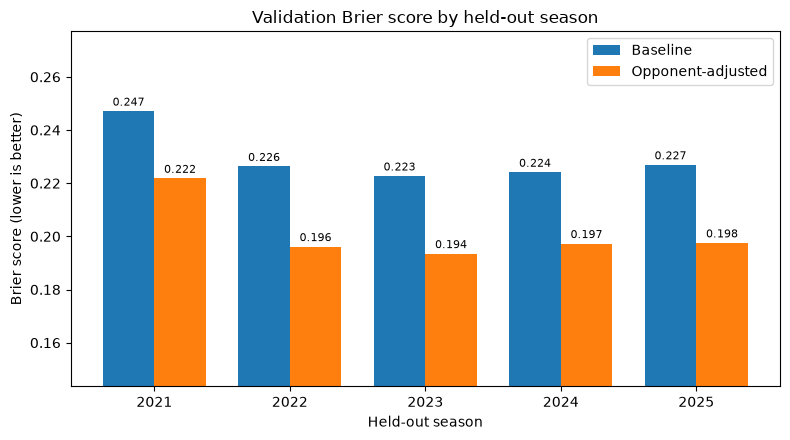

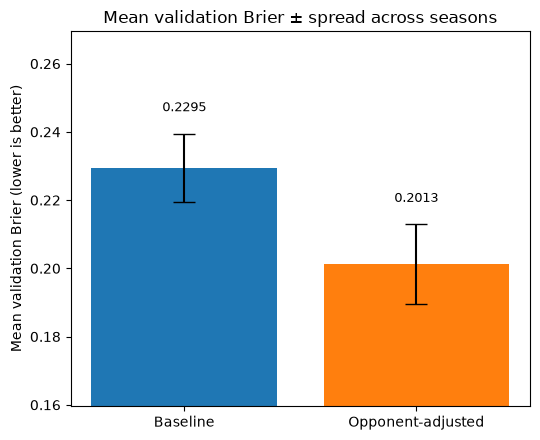

In [8]:
display(validation_results.round(4).style.hide(axis="index"))

seasons = sorted(fold_scores["heldout_season"].unique())
x = np.arange(len(seasons)); w = 0.38

# (a) grouped bars: Brier by held-out season
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, m in enumerate(MODEL_NAMES):
    vals = [fold_scores[(fold_scores.model == m) & (fold_scores.heldout_season == s)]["validation_brier"].iloc[0] for s in seasons]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=m)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(seasons)
ax.set_xlabel("Held-out season"); ax.set_ylabel("Brier score (lower is better)")
ax.set_title("Validation Brier score by held-out season")
lo = fold_scores["validation_brier"].min()
ax.set_ylim(max(0, lo - 0.05), fold_scores["validation_brier"].max() + 0.03)
ax.legend(); fig.tight_layout()
fig.savefig(FIG_DIR / "h1_validation_brier_by_season.png", dpi=150); plt.show()

# (b) mean validation Brier with spread (SD) error bars
fig, ax = plt.subplots(figsize=(5.5, 4.5))
means = validation_results["Mean validation Brier"].values
spread = validation_results["Spread"].values
bars = ax.bar(MODEL_NAMES, means, yerr=spread, capsize=8, color=["tab:blue", "tab:orange"])
ax.bar_label(bars, fmt="%.4f", padding=14, fontsize=9)
ax.set_ylabel("Mean validation Brier (lower is better)")
ax.set_title("Mean validation Brier ± spread across seasons")
ax.set_ylim(max(0, (means - spread).min() - 0.03), (means + spread).max() + 0.03)
fig.tight_layout(); fig.savefig(FIG_DIR / "h1_mean_validation_brier.png", dpi=150); plt.show()

## 9. Choose a model and score the 2026 final test

The model is chosen **from the validation results only**: the lowest mean validation Brier wins (ties go to the simpler baseline). The selected model is then refit on all seasons through 2025 (excluding 2020), and its Brier score on the 2026 games is computed **once**. The 2026 score is never used to change the model choice.

In [9]:
ranked = validation_results.sort_values("Mean validation Brier").reset_index(drop=True)
if abs(ranked.loc[0, "Mean validation Brier"] - ranked.loc[1, "Mean validation Brier"]) < 1e-9:
    SELECTED = "Baseline"
else:
    SELECTED = ranked.loc[0, "Model"]
OTHER = [m for m in MODEL_NAMES if m != SELECTED][0]
print(f"Selected from validation: {SELECTED} "
      f"(mean validation Brier {ranked.set_index('Model').loc[SELECTED, 'Mean validation Brier']:.4f} vs "
      f"{ranked.set_index('Model').loc[OTHER, 'Mean validation Brier']:.4f} for {OTHER})")

final_train = base_df[base_df[SEASON_COL].isin(FINAL_TRAIN_SEASONS)]
final_test = base_df[base_df[SEASON_COL] == 2026]
assert sorted(final_train[SEASON_COL].unique()) == FINAL_TRAIN_SEASONS, "Training data does not match the manifest final fit"

FINAL_FITS = {}  # model name -> network fitted on seasons through 2025 (reused in Section 10)
FINAL_FITS[SELECTED] = fit_model(SELECTED, final_train)

p_test = predict_win_prob(FINAL_FITS[SELECTED], final_test[MODELS[SELECTED]])
p_train_final = predict_win_prob(FINAL_FITS[SELECTED], final_train[MODELS[SELECTED]])
test_brier = brier(final_test[BINARY], p_test)          # computed once
final_train_brier = brier(final_train[BINARY], p_train_final)

final_preds = final_test[INPUT_COLS_ALL + [TARGET, BINARY, SEASON_COL]].copy()
final_preds.insert(0, "model", SELECTED)
final_preds["p_win"] = p_test
final_preds["brier"] = (final_preds[BINARY] - final_preds["p_win"]) ** 2
final_preds_path = OUT_DIR / "h1_final_test_predictions.csv"
final_preds.to_csv(final_preds_path, index=False)

final_run_id = log_run(
    f"final_test__{SELECTED}", "final_test_2026",
    {"model_name": SELECTED, "input_columns": ", ".join(MODELS[SELECTED]), "target": TARGET,
     "train_seasons": ", ".join(map(str, FINAL_TRAIN_SEASONS)), "test_season": 2026,
     "selection_rule": "lowest mean validation Brier", **settings_params()},
    {"final_train_brier": final_train_brier, "test_brier_2026": test_brier},
    [final_preds_path])

print(f"{SELECTED} 2026 test Brier score: {test_brier:.4f}  (n = {len(final_test):,} team-game rows)")

Selected from validation: Opponent-adjusted (mean validation Brier 0.2013 vs 0.2295 for Baseline)


C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})


Opponent-adjusted 2026 test Brier score: 0.2003  (n = 10,544 team-game rows)


## 10. Make the Team A–Team C predictions

Both models estimate Team A's and Team C's chance of winning in the same shared 2026 situations. Each situation gives both teams a **matching opponent rating group and game location** (the teams do not necessarily play the same actual opponent). This uses predicted chances only, never actual outcomes.

The selected model's fit through 2025 is reused from Section 9. The other model is fitted once on the same seasons with the same settings, only if that fit does not already exist.

In [10]:
def get_or_fit_final(model_name):
    if model_name in FINAL_FITS:
        print(f"Reusing existing fit through 2025 for {model_name}")
        return FINAL_FITS[model_name]
    print(f"Fitting {model_name} once on seasons {FINAL_TRAIN_SEASONS[0]}–{FINAL_TRAIN_SEASONS[-1]} (excluding 2020)")
    FINAL_FITS[model_name] = fit_model(model_name, final_train)
    p_tr = predict_win_prob(FINAL_FITS[model_name], final_train[MODELS[model_name]])
    log_run(f"final_fit__{model_name}", "final_fit_through_2025",
            {"model_name": model_name, "input_columns": ", ".join(MODELS[model_name]), "target": TARGET,
             "train_seasons": ", ".join(map(str, FINAL_TRAIN_SEASONS)),
             "purpose": "Team A vs Team C shared-situation comparison", **settings_params()},
            {"final_train_brier": brier(final_train[BINARY], p_tr)})
    return FINAL_FITS[model_name]

for m in (SELECTED, OTHER):
    get_or_fit_final(m)

assert not any(c in scenarios.columns for c in (TARGET, BINARY))
pred_rows = []
for m in MODEL_NAMES:
    p = predict_win_prob(FINAL_FITS[m], scenarios[MODELS[m]])
    pred_rows.append(pd.DataFrame({
        "scenario_id": scenarios[SCEN_ID].values, "model_name": m,
        "focal_team_id": scenarios[TEAM_COL].values, "team": scenarios["team_label"].values,
        "predicted_win_probability": p}))
team_preds = pd.concat(pred_rows, ignore_index=True)
team_preds_path = OUT_DIR / "h1_team_comparison_predictions.csv"
team_preds.to_csv(team_preds_path, index=False)
team_preds.head()

Reusing existing fit through 2025 for Opponent-adjusted
Fitting Baseline once on seasons 2015–2025 (excluding 2020)


C:\Users\edwar\AppData\Local\Temp\ipykernel_32328\1793053148.py:24: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(net, data, state_names={c: STATE_NAMES[c] for c in inputs + [TARGET]})


,scenario_id,model_name,focal_team_id,team,predicted_win_probability
0,S0001,Baseline,1105,Team A,0.730726
1,S0001,Baseline,1120,Team C,0.628277
2,S0002,Baseline,1105,Team A,0.730726
3,S0002,Baseline,1120,Team C,0.628277
4,S0003,Baseline,1105,Team A,0.730726


## 11. Summarize the Team A–Team C comparison

For each model we average Team A's predicted chances and Team C's predicted chances over the same shared situations (matching opponent rating group and location), then compute **Difference = Team A average − Team C average**. A positive difference means that model gives Team A the higher average chance of winning.

Model,Team A average predicted chance,Team C average predicted chance,Difference (Team A - Team C),Number of shared situations
Baseline,0.612900,0.510300,0.102600,58
Opponent-adjusted,0.713800,0.510200,0.203600,58


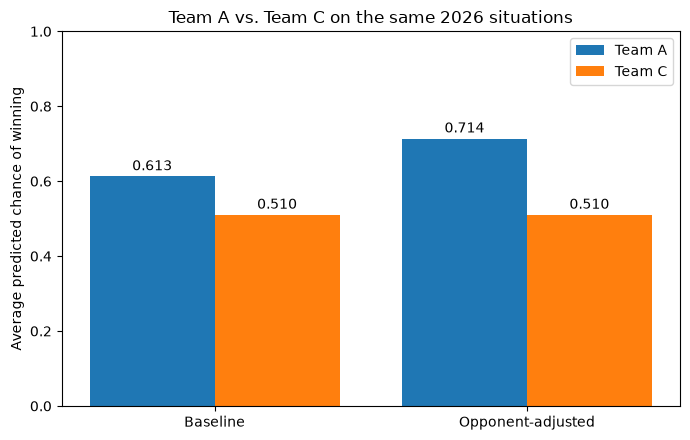

h1_mlflow_runs.csv now contains 26 runs


In [11]:
avg = team_preds.groupby(["model_name", "team"])["predicted_win_probability"].mean().unstack("team")
summary = pd.DataFrame({
    "Model": MODEL_NAMES,
    "Team A average predicted chance": [avg.loc[m, "Team A"] for m in MODEL_NAMES],
    "Team C average predicted chance": [avg.loc[m, "Team C"] for m in MODEL_NAMES],
})
summary["Difference (Team A - Team C)"] = summary["Team A average predicted chance"] - summary["Team C average predicted chance"]
summary["Number of shared situations"] = scenarios[SCEN_ID].nunique()
summary_path = OUT_DIR / "h1_team_comparison_summary.csv"
summary.to_csv(summary_path, index=False)
display(summary.round(4).style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(7, 4.5))
xx = np.arange(len(MODEL_NAMES))
b1 = ax.bar(xx - 0.2, summary["Team A average predicted chance"], 0.4, label="Team A")
b2 = ax.bar(xx + 0.2, summary["Team C average predicted chance"], 0.4, label="Team C")
ax.bar_label(b1, fmt="%.3f", padding=2); ax.bar_label(b2, fmt="%.3f", padding=2)
ax.set_xticks(xx); ax.set_xticklabels(MODEL_NAMES)
ax.set_ylabel("Average predicted chance of winning"); ax.set_ylim(0, 1)
ax.set_title("Team A vs. Team C on the same 2026 situations")
ax.legend(); fig.tight_layout()
fig.savefig(FIG_DIR / "h1_team_comparison.png", dpi=150); plt.show()

# Log the comparison and re-export the full MLflow table (now includes final-test and comparison runs)
log_run("team_comparison__shared_2026", "team_comparison",
        {"models": ", ".join(MODEL_NAMES), "scenario_file": "h1_shared_2026_scenarios.csv",
         "n_scenarios": scenarios[SCEN_ID].nunique(), "fits_used": f"seasons {FINAL_TRAIN_SEASONS[0]}–2025 excl. 2020",
         **settings_params()},
        {f"diff_{m.replace(' ', '_').lower()}": summary.set_index("Model").loc[m, "Difference (Team A - Team C)"] for m in MODEL_NAMES},
        [team_preds_path, summary_path])
mlflow_runs = export_mlflow_runs()
print(f"h1_mlflow_runs.csv now contains {len(mlflow_runs)} runs")

## 12. Write the H1 result

The cell below writes the H1 verdict with the numbers from this run, shows it here, and saves it as `h1_verdict.md`. It reports each model's validation Brier scores, the model selected and why, the selected model's 2026 test Brier, the Team A / Team C average chances and differences, and whether adding opponent strength changed the comparison.

The two conclusions are kept separate: the **2026 Brier score** measures the selected model's accuracy; the **shared-situation predictions** answer the Team A–Team C question.

In [ ]:
vr = validation_results.set_index("Model")
sm = summary.set_index("Model")
season_cols = [c for c in validation_results.columns if c.endswith(" Brier") and c[:4].isdigit()]

# Per-season winner count (stability)
piv = fold_scores.pivot(index="heldout_season", columns="model", values="validation_brier")
wins = {m: int((piv[m] < piv[[x for x in MODEL_NAMES if x != m][0]]).sum()) for m in MODEL_NAMES}
stable_note = (f"{SELECTED} had the lower Brier in {wins[SELECTED]} of {len(piv)} held-out seasons.")

base_diff = sm.loc["Baseline", "Difference (Team A - Team C)"]
adj_diff = sm.loc["Opponent-adjusted", "Difference (Team A - Team C)"]
shift = adj_diff - base_diff
pct = lambda v: f"{v * 100:.1f}%"
A_base, C_base = sm.loc["Baseline", "Team A average predicted chance"], sm.loc["Baseline", "Team C average predicted chance"]
A_adj, C_adj = sm.loc["Opponent-adjusted", "Team A average predicted chance"], sm.loc["Opponent-adjusted", "Team C average predicted chance"]
n_scen = scenarios[SCEN_ID].nunique()

if adj_diff > 0:
    verdict = (f"**H1's prediction was supported.** The opponent-adjusted model estimated Team A at {pct(A_adj)} and Team C at {pct(C_adj)} "
               f"on the shared situations (matching opponent rating group and location), so Team A has the higher estimated chance of winning.")
    if base_diff > 0:
        verdict += ("\n\n**Limitation:** the baseline model already favored Team A "
                    f"({pct(A_base)} vs. {pct(C_base)}), so Team A was ahead before opponent strength was added. Including opponent rating group "
                    f"changed the gap from {base_diff * 100:+.1f} to {adj_diff * 100:+.1f} percentage points "
                    f"(Team A moved {round((A_adj - A_base) * 100, 1) + 0:+.1f} points; Team C moved {round((C_adj - C_base) * 100, 1) + 0:+.1f}). "
                    "We therefore cannot say that opponent strength alone caused the difference between the teams.")
    else:
        verdict += (f"\n\nUnder the baseline, Team C was ahead or level ({pct(A_base)} vs. {pct(C_base)}), so including opponent strength reversed the comparison.")
else:
    verdict = (f"**H1's prediction was not supported.** After opponent strength is included, Team A ({pct(A_adj)}) does not have a higher "
               f"average predicted chance than Team C ({pct(C_adj)}).")

lines = ["# H1 Verdict", "", "## Validation (Brier score, lower is better)", ""]
lines += ["| Model | " + " | ".join(season_cols) + " | Mean | Spread (SD) | Train-validation gap |",
          "|---|" + "---:|" * (len(season_cols) + 3)]
for m in MODEL_NAMES:
    lines.append(f"| {m} | " + " | ".join(f"{vr.loc[m, c]:.4f}" for c in season_cols) +
                 f" | {vr.loc[m, 'Mean validation Brier']:.4f} | {vr.loc[m, 'Spread']:.4f} | {vr.loc[m, 'Train-validation gap']:.4f} |")
lines += ["", f"**Stability:** {stable_note} Spread across seasons: "
          + ", ".join(f"{m} {vr.loc[m, 'Spread']:.4f}" for m in MODEL_NAMES) + ".",
          "", "## Model selected for the final test", "",
          f"**{SELECTED}** was selected because it had the lower mean validation Brier "
          f"({vr.loc[SELECTED, 'Mean validation Brier']:.4f} vs {vr.loc[OTHER, 'Mean validation Brier']:.4f} for {OTHER}).",
          f"Its 2026 test Brier score (fit on 2015–2019 and 2021–2025, scored once) is **{test_brier:.4f}**.",
          "", "## Team A vs. Team C on shared 2026 situations", "",
          f"The comparison uses `h1_shared_2026_scenarios.csv` ({n_scen} situations, one row per team in each, {len(scenarios)} rows). "
          "In every situation Team A and Team C have a matching opponent rating group and game location. "
          f"Team A = team id {TEAM_A_ID} and Team C = team id {TEAM_C_ID}. No game outcomes are used.", "",
          "| Model | Team A avg chance | Team C avg chance | Difference (A - C) |", "|---|---:|---:|---:|"]
for m in MODEL_NAMES:
    lines.append(f"| {m} | {pct(sm.loc[m, 'Team A average predicted chance'])} | {pct(sm.loc[m, 'Team C average predicted chance'])} | {sm.loc[m, 'Difference (Team A - Team C)'] * 100:+.1f} pts |")
lines += ["", f"Adding opponent strength changed the Team A − Team C difference by {shift * 100:+.1f} percentage points "
          f"(from {base_diff * 100:+.1f} to {adj_diff * 100:+.1f}).", "", "## Verdict", "", verdict, "",
          "*Caveats: results are point estimates with no uncertainty intervals; the 2026 Brier score (accuracy) and the "
          "shared-situation comparison answer different questions and should be read separately.*"]
verdict_md = "\n".join(lines)
(OUT_DIR / "h1_verdict.md").write_text(verdict_md, encoding="utf-8")
display(Markdown(verdict_md))

# Final bookkeeping: confirm required outputs exist
mlflow_runs = export_mlflow_runs()
required_outputs = [DATA_DIR / "h1_shared_2026_scenarios.csv", OUT_DIR / "h1_validation_results.csv",
                    OUT_DIR / "h1_mlflow_runs.csv", OUT_DIR / "h1_final_test_predictions.csv",
                    OUT_DIR / "h1_team_comparison_predictions.csv", OUT_DIR / "h1_team_comparison_summary.csv",
                    OUT_DIR / "h1_verdict.md"] + sorted(FIG_DIR.glob("*.png"))
for p in required_outputs:
    print(("OK      " if p.exists() else "MISSING ") + str(p.relative_to(ROOT)))